In [15]:
import torch
import torch.nn as nn
import json
import matplotlib.pyplot as plt
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from IPython.display import clear_output

In [16]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

Using device: cuda


In [17]:
batch_size = 512
learning_rate = 3e-4
num_epochs = 10
n_classes = 5
crop_size = 32

In [18]:
with open(f'data/dataset_attributs/train_{crop_size}x{crop_size}_data.json', 'r', encoding='utf-8') as f:
    train_data = json.load(f)

with open(f'data/dataset_attributs/val_{crop_size}x{crop_size}_data.json', 'r', encoding='utf-8') as f:
    val_data = json.load(f)

# with open(f'data/dataset_attributs/test_{crop_size}x{crop_size}_data.json', 'r', encoding='utf-8') as f:
#     test_data = json.load(f)


class CropDataset(Dataset):

    def __init__(self, split):
        self.samples = []

        if split == 'train':
            data = train_data
        elif split == 'val':
            data = val_data
        # elif split == 'test':
        #     data = test_data

        for path_to_img, crops in data.items():
            for crop in crops:
                x = torch.tensor(crop["x"], dtype=torch.float32)
                y = torch.tensor(crop["y"], dtype=torch.int64)
                self.samples.append((x, y))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return x, y
    

train_dataset = CropDataset(split='train')
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

val_dataset = CropDataset(split='val')
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

# test_dataset = CropDataset(split='test')
# test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)
# test_iterator = iter(test_loader)

In [19]:
# class NeuralNetwork(torch.nn.Module):

#     def __init__(self):
#         super().__init__()
#         self.layer1 = nn.Sequential(
#             nn.Linear(15*4, 64),
#             nn.BatchNorm1d(64),
#             nn.ReLU()
#         )
#         self.layer2 = nn.Sequential(
#             nn.Linear(64, 32),
#             nn.BatchNorm1d(32),
#             nn.ReLU()
#         )
#         self.layer3 = nn.Sequential(
#             nn.Linear(32, n_classes)
#         )

#     def forward(self, x):
#         x = self.layer1(x)
#         x = self.layer2(x)
#         x = self.layer3(x)
#         return x

In [20]:
class NeuralNetwork(torch.nn.Module):

    def __init__(self):
        super().__init__()
        self.layer1 = nn.Sequential(
            nn.Linear(15*4, n_classes)
        )

    def forward(self, x):
        x = self.layer1(x)
        return x

In [25]:
model = NeuralNetwork().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in the model: {total_params}")

train_loss_list, val_loss_list = [], []
train_acc_list, val_acc_list = [], []

Total parameters in the model: 305


In [26]:
def get_accuracy(split, iterator):
    if split == "train":
        loader = train_loader
    elif split == "val":
        loader = val_loader
    # elif split == "test":
    #     loader = test_loader
    else:
        print("split non définit")
        return None

    model.eval()
    with torch.no_grad():
        try:
            x, y = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            x, y = next(iterator)
        x, y = x.to(device), y.to(device)
        y_hat = model(x)
        probs = torch.softmax(y_hat, dim=1)
        preds = torch.argmax(probs, dim=1)
        n_correct = (preds.view(-1) == y.view(-1)).float().sum().item()
        n_total = y.shape[0]
    accuracy = n_correct / n_total
    model.train()
    return accuracy, iterator

In [27]:
def moving_average(x, w=10):
    smoothed = []
    for i in range(len(x)):
        start = max(0, i - w + 1)
        window = x[start:i+1]
        smoothed.append(sum(window) / len(window))
    return smoothed

moyenne sur les 100 dernières valeurs:   train_acc: 0.946209192276001   val_acc: 0.9589765071868896


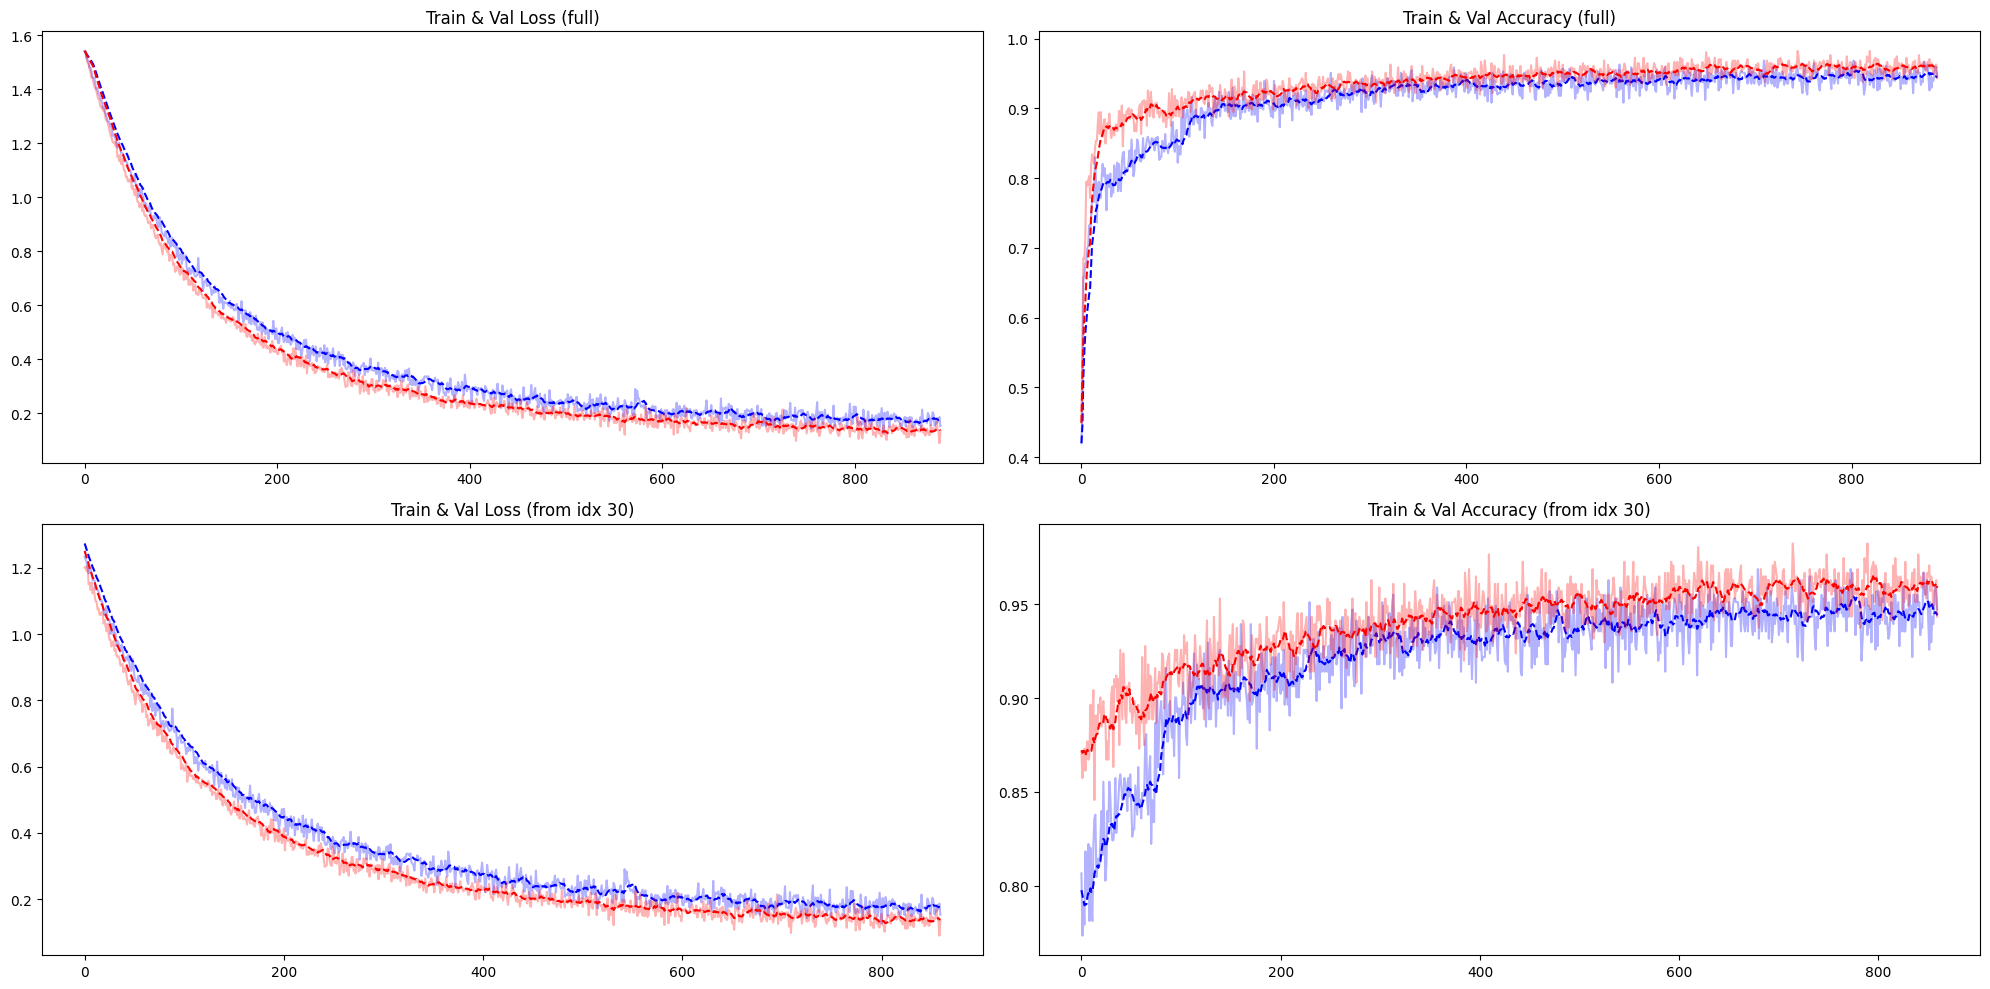

In [28]:
for epoch in range(num_epochs):
    for i, (x, y) in tqdm(enumerate(train_loader), total=len(train_loader)):

        x, y = x.to(device), y.to(device)

        y_pred = model(x)
        loss = criterion(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()



        if i % 10 == 0:
            train_loss_list.append(loss.item())

            # get val loss
            model.eval()
            with torch.no_grad():
                try:
                    x, y = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    x, y = next(val_iterator)
                x, y = x.to(device), y.to(device)
                y_pred = model(x)
                val_loss = criterion(y_pred, y)
                val_loss_list.append(val_loss.item())
            model.train()

            # get accuracy
            train_acc, train_iterator = get_accuracy("train", train_iterator)
            val_acc, val_iterator = get_accuracy("val", val_iterator)
            train_acc_list.append(train_acc)
            val_acc_list.append(val_acc)



    train_loss_list_smoothed = moving_average(train_loss_list)
    val_loss_list_smoothed = moving_average(val_loss_list)
    train_acc_list_smoothed = moving_average(train_acc_list)
    val_acc_list_smoothed = moving_average(val_acc_list)

    clear_output(wait=True)  # efface l'ancien plot

    print(f"moyenne sur les 100 dernières valeurs:   train_acc: {torch.tensor([train_acc_list_smoothed[-100:]]).mean()}   val_acc: {torch.tensor([val_acc_list_smoothed[-100:]]).mean()}")

    plt.figure(figsize=(20, 10))  # plus grand pour 4 sous-plots

    # 1er plot (train+val loss, full)
    plt.subplot(2, 2, 1)
    plt.plot(train_loss_list, c="blue", alpha=0.3)
    plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
    plt.plot(val_loss_list, c="red", alpha=0.3)
    plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
    plt.title("Train & Val Loss (full)")

    # 2e plot (train+val acc, full)
    plt.subplot(2, 2, 2)
    plt.plot(train_acc_list, c="blue", alpha=0.3)
    plt.plot(train_acc_list_smoothed, c="blue", linestyle='--')
    plt.plot(val_acc_list, c="red", alpha=0.3)
    plt.plot(val_acc_list_smoothed, c="red", linestyle='--')
    plt.title("Train & Val Accuracy (full)")

    # 3e plot (train+val loss, from index 30)
    plt.subplot(2, 2, 3)
    plt.plot(train_loss_list[30:], c="blue", alpha=0.3)
    plt.plot(train_loss_list_smoothed[30:], c="blue", linestyle='--')
    plt.plot(val_loss_list[30:], c="red", alpha=0.3)
    plt.plot(val_loss_list_smoothed[30:], c="red", linestyle='--')
    plt.title("Train & Val Loss (from idx 30)")

    # 4e plot (train+val acc, from index 30)
    plt.subplot(2, 2, 4)
    plt.plot(train_acc_list[30:], c="blue", alpha=0.3)
    plt.plot(train_acc_list_smoothed[30:], c="blue", linestyle='--')
    plt.plot(val_acc_list[30:], c="red", alpha=0.3)
    plt.plot(val_acc_list_smoothed[30:], c="red", linestyle='--')
    plt.title("Train & Val Accuracy (from idx 30)")

    plt.tight_layout()  # ajuste l'espacement
    plt.show()


In [29]:
# sauvegarder les poids du modèle et les paramètres d'entraînement

torch.save({
    'epoch': epoch+1,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': torch.tensor([train_acc_list_smoothed[-100:]]).mean(),
}, f"weights/regression_{crop_size}x{crop_size}_checkpoint10.pth")